# Faster R-CNN на датасете RTSD — Версия 2: Модифицированный backbone

**Модифицированная архитектура**: ResNet50+FPN backbone с весами от COCO  
(ImageNet → COCO — максимально полезный старт для детекции),  
затем рекурсивная замена `BatchNorm2d` → `GroupNorm(num_groups=32)` и `ReLU` → `SiLU`.  
Conv-веса backbone переносятся через `strict=False`, GN инициализируется заново.

## 1. Установка зависимостей

## 2. Импорты

In [1]:
import os
import json
import numpy as np
import torch
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import defaultdict, Counter
import torchvision.transforms.functional as F
import time

print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Устройство: {device}")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA доступна: True
Устройство: cuda


## 3. Настройки путей

Укажи путь к папке с датасетом.

In [2]:
import os

# === УКАЖИ ПУТЬ К ДАТАСЕТУ ===
# В Colab путь начинается от /content/ и далее имя папки, которую мы создали при unzip
DATASET_ROOT = 'rtsd_data'

TRAIN_ANNO  = os.path.join(DATASET_ROOT, 'train_anno.json')
VAL_ANNO    = os.path.join(DATASET_ROOT, 'val_anno.json')
LABEL_MAP   = os.path.join(DATASET_ROOT, 'label_map.json')
FRAMES_DIR  = os.path.join(DATASET_ROOT, 'rtsd-frames', 'rtsd-frames')


# Параметры обучения
MIN_INSTANCES_PER_CLASS = 50
BATCH_SIZE  = 2
NUM_EPOCHS  = 2
LR          = 0.005
MOMENTUM    = 0.9
WEIGHT_DECAY = 0.0005

print("Пути настроены для Google Colab.")
print(f"Папка с данными: {DATASET_ROOT}")
print(f"Существует ли папка с кадрами: {os.path.exists(FRAMES_DIR)}")

# Если выведет False, запустите команду !ls /content/rtsd_data, чтобы увидеть точные имена папок


Пути настроены для Google Colab.
Папка с данными: rtsd_data
Существует ли папка с кадрами: True


## 4. Анализ датасета и фильтрация редких классов

Train: 54188 изображений, 95518 объектов
Val:   5000 изображений, 8866 объектов
Классов в label_map: 155

Всего классов в train: 155
Макс объектов в классе: 22155
Мин объектов в классе:  1

Топ-30 классов: [1, 2, 3, 4, 5, 6, 7, 8, 10, 13, 15, 17, 22, 23, 25, 26, 32, 33, 35, 40, 41, 43, 47, 52, 54, 55, 63, 69, 71, 82]
NUM_CLASSES (включая фон): 31

После выбора топ-30:
Train: 48246 изображений, 79847 объектов

После балансировки (макс 1000 картинок на класс):
Train: 24028 изображений, 42820 объектов


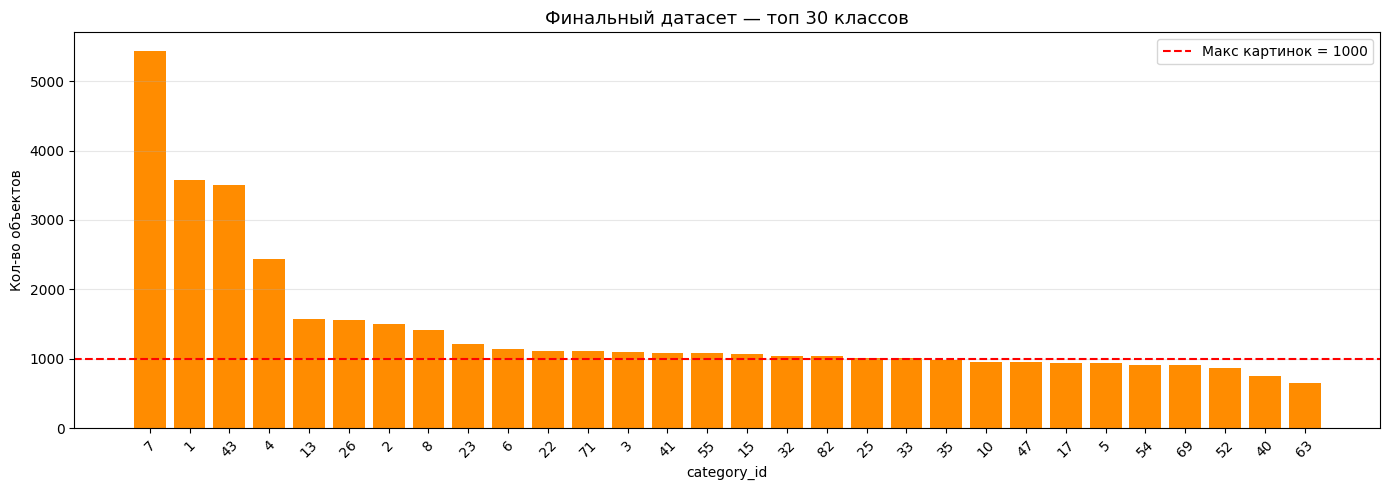

In [3]:
# Загружаем аннотации
with open(TRAIN_ANNO, 'r') as f:
    train_data = json.load(f)

with open(VAL_ANNO, 'r') as f:
    val_data = json.load(f)

with open(LABEL_MAP, 'r') as f:
    label_map = json.load(f)

print(f"Train: {len(train_data['images'])} изображений, {len(train_data['annotations'])} объектов")
print(f"Val:   {len(val_data['images'])} изображений, {len(val_data['annotations'])} объектов")
print(f"Классов в label_map: {len(label_map)}")

# Подсчёт классов
class_counts = Counter()
for ann in train_data['annotations']:
    class_counts[ann['category_id']] += 1

print(f"\nВсего классов в train: {len(class_counts)}")
print(f"Макс объектов в классе: {max(class_counts.values())}")
print(f"Мин объектов в классе:  {min(class_counts.values())}")

# Берём топ-30 классов по количеству объектов
TOP_N = 30
MAX_IMAGES_PER_CLASS = 1000

top_classes   = {cat_id for cat_id, _ in class_counts.most_common(TOP_N)}
cat_id_to_new = {old: new for new, old in enumerate(sorted(top_classes), start=1)}
NUM_CLASSES   = len(top_classes) + 1
print(f"\nТоп-{TOP_N} классов: {sorted(top_classes)}")
print(f"NUM_CLASSES (включая фон): {NUM_CLASSES}")

# Фильтруем аннотации под топ-30
train_anns_filtered = [a for a in train_data['annotations'] if a['category_id'] in top_classes]
val_anns_filtered   = [a for a in val_data['annotations']   if a['category_id'] in top_classes]

train_img_ids = {a['image_id'] for a in train_anns_filtered}
val_img_ids   = {a['image_id'] for a in val_anns_filtered}

train_imgs_filtered = [img for img in train_data['images'] if img['id'] in train_img_ids]
val_imgs_filtered   = [img for img in val_data['images']   if img['id'] in val_img_ids]

print(f"\nПосле выбора топ-{TOP_N}:")
print(f"Train: {len(train_imgs_filtered)} изображений, {len(train_anns_filtered)} объектов")

# Считаем до балансировки
class_counts_top = Counter()
for ann in train_anns_filtered:
    class_counts_top[ann['category_id']] += 1

# Балансировка — максимум 1000 картинок на класс
from collections import defaultdict

cat_to_imgs = defaultdict(list)
for ann in train_anns_filtered:
    cat_to_imgs[ann['category_id']].append(ann['image_id'])

imgs_to_keep = set()
for cat_id, img_ids in cat_to_imgs.items():
    unique_imgs = list(dict.fromkeys(img_ids))
    if len(unique_imgs) >= MAX_IMAGES_PER_CLASS:
        imgs_to_keep.update(unique_imgs[:MAX_IMAGES_PER_CLASS])
    else:
        imgs_to_keep.update(unique_imgs)

train_imgs_filtered = [img for img in train_imgs_filtered if img['id'] in imgs_to_keep]
train_anns_filtered = [a   for a   in train_anns_filtered if a['image_id'] in imgs_to_keep]

print(f"\nПосле балансировки (макс {MAX_IMAGES_PER_CLASS} картинок на класс):")
print(f"Train: {len(train_imgs_filtered)} изображений, {len(train_anns_filtered)} объектов")

# Финальный подсчёт
class_counts_final = Counter()
for ann in train_anns_filtered:
    class_counts_final[ann['category_id']] += 1

# Гистограмма финального датасета
sorted_final = sorted(class_counts_final.items(), key=lambda x: -x[1])

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar([str(x[0]) for x in sorted_final], [x[1] for x in sorted_final], color='darkorange')
ax.axhline(y=MAX_IMAGES_PER_CLASS, color='red', linestyle='--', label=f'Макс картинок = {MAX_IMAGES_PER_CLASS}')
ax.set_title(f'Финальный датасет — топ {TOP_N} классов', fontsize=13)
ax.set_xlabel('category_id')
ax.set_ylabel('Кол-во объектов')
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('class_distribution_final.png', dpi=100)
plt.show()

## 5. Dataset класс

In [4]:
class RTSDDataset(Dataset):
    def __init__(self, images, annotations, frames_dir, cat_id_to_new, transforms=None):
        """
        images       — список словарей {id, file_name, width, height}
        annotations  — список словарей {image_id, category_id, bbox, area, iscrowd}
        frames_dir   — путь к папке с кадрами
        cat_id_to_new — маппинг старых category_id в новые (1, 2, 3...)
        """
        self.images      = images
        self.frames_dir  = frames_dir
        self.cat_id_to_new = cat_id_to_new
        self.transforms  = transforms

        # Строим словарь image_id -> список аннотаций
        self.img_to_anns = defaultdict(list)
        for ann in annotations:
            self.img_to_anns[ann['image_id']].append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_info = self.images[idx]
        img_id   = img_info['id']

        # Путь к картинке — file_name уже содержит 'rtsd-frames/name.jpg'
        # берём только имя файла
        fname    = os.path.basename(img_info['file_name'])
        img_path = os.path.join(self.frames_dir, fname)
        img      = Image.open(img_path).convert('RGB')

        anns = self.img_to_anns[img_id]

        boxes, labels = [], []
        for ann in anns:
            new_cat = self.cat_id_to_new.get(ann['category_id'])
            if new_cat is None:
                continue
            # COCO bbox: [x_min, y_min, width, height] -> [x1, y1, x2, y2]
            x, y, w, h = ann['bbox']
            x2, y2 = x + w, y + h
            # Защита от вырожденных bbox
            if w <= 0 or h <= 0:
                continue
            boxes.append([x, y, x2, y2])
            labels.append(new_cat)

        if len(boxes) == 0:
            boxes  = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros(0, dtype=torch.int64)
        else:
            boxes  = torch.as_tensor(boxes,  dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)

        area    = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0]) if len(boxes) > 0 else torch.zeros(0)
        iscrowd = torch.zeros(len(labels), dtype=torch.int64)

        target = {
            'boxes':    boxes,
            'labels':   labels,
            'image_id': torch.tensor([img_id]),
            'area':     area,
            'iscrowd':  iscrowd,
        }

        # Переводим в тензор
        img = F.to_tensor(img)

        if self.transforms:
            img, target = self.transforms(img, target)

        return img, target


def collate_fn(batch):
    return tuple(zip(*batch))


print("Dataset класс определён.")

Dataset класс определён.


## 6. DataLoader'ы

In [5]:
import random

# Делим наш отфильтрованный train на train / val / test
random.seed(42)
all_imgs = train_imgs_filtered.copy()
random.shuffle(all_imgs)

n_test = int(len(all_imgs) * 0.15)
n_val  = int(len(all_imgs) * 0.15)

test_imgs_split  = all_imgs[:n_test]
val_imgs_split   = all_imgs[n_test : n_test + n_val]
train_imgs_split = all_imgs[n_test + n_val:]

print(f"Train: {len(train_imgs_split)} | Val: {len(val_imgs_split)} | Test: {len(test_imgs_split)}")

# Аннотации для каждого split
train_ids = {img['id'] for img in train_imgs_split}
val_ids   = {img['id'] for img in val_imgs_split}
test_ids  = {img['id'] for img in test_imgs_split}

train_anns_split = [a for a in train_anns_filtered if a['image_id'] in train_ids]
val_anns_split   = [a for a in train_anns_filtered if a['image_id'] in val_ids]
test_anns_split  = [a for a in train_anns_filtered if a['image_id'] in test_ids]

# Датасеты
dataset_train = RTSDDataset(train_imgs_split, train_anns_split, FRAMES_DIR, cat_id_to_new)
dataset_val   = RTSDDataset(val_imgs_split,   val_anns_split,   FRAMES_DIR, cat_id_to_new)
dataset_test  = RTSDDataset(test_imgs_split,  test_anns_split,  FRAMES_DIR, cat_id_to_new)

data_loader_train = DataLoader(dataset_train, batch_size=2, shuffle=True,  collate_fn=collate_fn, num_workers=0)
data_loader_val   = DataLoader(dataset_val,   batch_size=2, shuffle=False, collate_fn=collate_fn, num_workers=0)
data_loader_test  = DataLoader(dataset_test,  batch_size=2, shuffle=False, collate_fn=collate_fn, num_workers=0)

print(f"Train batches: {len(data_loader_train)}")
print(f"Val batches:   {len(data_loader_val)}")
print(f"Test batches:  {len(data_loader_test)}")

Train: 16820 | Val: 3604 | Test: 3604
Train batches: 8410
Val batches:   1802
Test batches:  1802


## 7. Проверка датасета — визуализация примера

## 8. Модель — Faster R-CNN с модифицированным backbone (COCO → GroupNorm + SiLU)

**Версия 2**: берём backbone из предобученной `fasterrcnn_resnet50_fpn(COCO)`,  
рекурсивно заменяем `BatchNorm2d` → `GroupNorm(num_groups=32)` и `ReLU` → `SiLU`,  
переносим Conv-веса через `strict=False` — GN подстраивается за 1-2 эпохи.  

**Почему COCO, а не ImageNet:**  
ResNet50 внутри Faster R-CNN прошёл два этапа обучения: ImageNet (классификация) → COCO (детекция).  
Его backbone уже умеет не просто различать текстуры, но и "думать" в терминах объектов на фото —  
это лучший возможный старт для нашей задачи детекции дорожных знаков.

In [7]:
import torch
import torch.nn as nn
import torchvision
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.faster_rcnn import fasterrcnn_resnet50_fpn, FastRCNNPredictor
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.ops import MultiScaleRoIAlign

# ─────────────────────────────────────────────────────────────────────────
# Шаг 1: Функция рекурсивной замены нормализации и активации
# ─────────────────────────────────────────────────────────────────────────

def replace_bn_relu(module: nn.Module, num_groups: int = 32) -> nn.Module:
    """
    Рекурсивно обходит все подмодули и заменяет:
      - BatchNorm2d  →  GroupNorm(num_groups, num_channels)
      - ReLU         →  SiLU (Swish)
    Conv-веса при этом не трогаются — только структура нормализации и активации.
    Возвращает изменённый модуль (in-place).
    """
    for name, child in list(module.named_children()):
        if isinstance(child, nn.BatchNorm2d):
            num_channels = child.num_features
            # Если num_channels не делится на num_groups — уменьшаем groups
            g = num_groups
            while num_channels % g != 0 and g > 1:
                g //= 2
            new_norm = nn.GroupNorm(num_groups=g, num_channels=num_channels)
            setattr(module, name, new_norm)
        elif isinstance(child, nn.ReLU):
            # SiLU (Swish): x * sigmoid(x) — плавная нелинейность без нулевого градиента
            setattr(module, name, nn.SiLU(inplace=False))
        else:
            replace_bn_relu(child, num_groups)
    return module


# ─────────────────────────────────────────────────────────────────────────
# Шаг 2: Вытаскиваем backbone с COCO-весами из полной Faster R-CNN
# ─────────────────────────────────────────────────────────────────────────

# Загружаем полную Faster R-CNN pretrained на COCO
# ResNet50 внутри неё прошёл: ImageNet (классификация) → COCO (детекция)
# Это максимально полезный старт для нашей задачи
print("Загружаем fasterrcnn_resnet50_fpn с весами COCO...")
coco_model = fasterrcnn_resnet50_fpn(weights='DEFAULT')

# Вытаскиваем state_dict backbone (ResNet50 + FPN) — там уже COCO-знания
coco_backbone_state = coco_model.backbone.state_dict()
print(f"Извлечён backbone state_dict: {len(coco_backbone_state)} ключей")

# Освобождаем память от полной COCO-модели — она больше не нужна
del coco_model
torch.cuda.empty_cache()


# ─────────────────────────────────────────────────────────────────────────
# Шаг 3: Строим чистый backbone и применяем замену BN→GN, ReLU→SiLU
# ─────────────────────────────────────────────────────────────────────────

# Создаём backbone без весов — структура та же, что была в COCO-модели
backbone = resnet_fpn_backbone(
    backbone_name='resnet50',
    weights=None,           # Веса загрузим вручную из COCO ниже
    trainable_layers=5,     # Обучаем все слои backbone
)

# Применяем рекурсивную замену: BatchNorm2d→GroupNorm(32), ReLU→SiLU
# Conv-веса при этом не трогаются — меняется только структура
backbone = replace_bn_relu(backbone, num_groups=32)
print("Замена BatchNorm2d→GroupNorm(32) и ReLU→SiLU выполнена.")


# ─────────────────────────────────────────────────────────────────────────
# Шаг 4: Загружаем COCO Conv-веса через strict=False
#
# strict=False означает:
#   ✅ Ключи которые совпадают (Conv2d) — загружаются
#   ⚠️ Ключи BN (running_mean/var) — пропускаются, GN инициализируется заново
#   ⚠️ Лишние ключи из COCO — игнорируются
# ─────────────────────────────────────────────────────────────────────────

missing, unexpected = backbone.load_state_dict(coco_backbone_state, strict=False)
print(f"COCO Conv-веса загружены через strict=False.")
print(f"  Не найдено ключей (ожидаемо — GN не имеет running_mean/var): {len(missing)}")
print(f"  Лишних ключей из COCO (игнорируются): {len(unexpected)}")


# ─────────────────────────────────────────────────────────────────────────
# Шаг 5: Собираем полную Faster R-CNN с нашим модифицированным backbone
# ─────────────────────────────────────────────────────────────────────────

# AnchorGenerator для 5 уровней FPN — стандартные размеры
anchor_generator = AnchorGenerator(
    sizes=((32,), (64,), (128,), (256,), (512,)),
    aspect_ratios=((0.5, 1.0, 2.0),) * 5,
)

# RoI Align по всем уровням FPN
roi_pooler = MultiScaleRoIAlign(
    featmap_names=['0', '1', '2', '3'],
    output_size=7,
    sampling_ratio=2,
)

# Сборка Faster R-CNN с модифицированным backbone
model = FasterRCNN(
    backbone=backbone,
    num_classes=NUM_CLASSES,      # фон + 30 классов дорожных знаков
    rpn_anchor_generator=anchor_generator,
    box_roi_pool=roi_pooler,
)

model.to(device)

# Статистика
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nМодель собрана и перенесена на {device}.")
print(f"Всего параметров:     {total_params:,}")
print(f"Обучаемых параметров: {trainable_params:,}")
print(f"NUM_CLASSES = {NUM_CLASSES} (включая фон)")

# Быстрая проверка — один forward pass
model.eval()
with torch.no_grad():
    dummy = [torch.zeros(3, 224, 224).to(device)]
    _ = model(dummy)
print("Forward pass прошёл успешно — модель готова к обучению.")
model.train()


Загружаем fasterrcnn_resnet50_fpn с весами COCO...


Извлечён backbone state_dict: 281 ключей
Замена BatchNorm2d→GroupNorm(32) и ReLU→SiLU выполнена.
COCO Conv-веса загружены через strict=False.
  Не найдено ключей (ожидаемо — GN не имеет running_mean/var): 0
  Лишних ключей из COCO (игнорируются): 0

Модель собрана и перенесена на cuda.
Всего параметров:     41,447,786
Обучаемых параметров: 41,447,786
NUM_CLASSES = 31 (включая фон)
Forward pass прошёл успешно — модель готова к обучению.


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): SiLU()
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=1e-05)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=1e-05)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=1e-05)
          (relu): SiLU()
  

## 9. Оптимизатор и LR scheduler

In [8]:
params = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.SGD(
    params,
    lr           = LR,
    momentum     = MOMENTUM,
    weight_decay = WEIGHT_DECAY,
)

# Уменьшаем LR на epoch 8 и 12
lr_scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones = [8, 12],
    gamma      = 0.1,
)

print(f"Оптимизатор: SGD | lr={LR} | momentum={MOMENTUM} | weight_decay={WEIGHT_DECAY}")
print(f"LR scheduler: MultiStepLR | milestones=[8, 12] | gamma=0.1")

Оптимизатор: SGD | lr=0.005 | momentum=0.9 | weight_decay=0.0005
LR scheduler: MultiStepLR | milestones=[8, 12] | gamma=0.1


## 10. Вспомогательные функции для COCO evaluate

Используем `engine.py` и `coco_eval.py` из torchvision references.  
Если их нет — скачиваем прямо здесь.

In [9]:
import urllib.request, os

BASE = 'https://raw.githubusercontent.com/pytorch/vision/main/references/detection/'
for fname in ['engine.py', 'coco_eval.py', 'coco_utils.py', 'utils.py']:
    if not os.path.exists(fname):
        urllib.request.urlretrieve(BASE + fname, fname)
        print(f'Скачан: {fname}')
    else:
        print(f'Уже есть: {fname}')

from engine import train_one_epoch, evaluate
print('engine.py подключён.')

Уже есть: engine.py
Уже есть: coco_eval.py
Уже есть: coco_utils.py
Уже есть: utils.py
engine.py подключён.


## 11. Цикл обучения с полными метриками

In [ ]:
# Train losses
losses_hist, loss_box_reg, loss_rpn_box_reg, loss_classifier, loss_objectness = [], [], [], [], []

# Val losses
val_losses, val_loss_box_reg, val_loss_rpn_box_reg, val_loss_classifier, val_loss_objectness = [], [], [], [], []

# COCO метрики (12 штук): AP/AR по IoU, размеру объекта и т.д.
stat0,stat1,stat2,stat3,stat4,stat5,stat6,stat7,stat8,stat9,stat10,stat11 = [],[],[],[],[],[],[],[],[],[],[],[]

best_val_loss = float('inf')

print(f"Начинаем обучение: {NUM_EPOCHS} эпох | устройство: {device}")
print("=" * 60)

for epoch in range(NUM_EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{NUM_EPOCHS} ---")

    # --- Train ---
    metrics = train_one_epoch(model, optimizer, data_loader_train, device, epoch, print_freq=50)
    print(f"\nmetrics")
    losses_hist.append(float(str(metrics.meters['loss']).split(' ')[0]))
    print(f"\nlosses_hist")
    loss_box_reg.append(float(str(metrics.meters['loss_box_reg']).split(' ')[0]))
    loss_rpn_box_reg.append(float(str(metrics.meters['loss_rpn_box_reg']).split(' ')[0]))
    loss_classifier.append(float(str(metrics.meters['loss_classifier']).split(' ')[0]))
    loss_objectness.append(float(str(metrics.meters['loss_objectness']).split(' ')[0]))
    print(f"\n--- Epoch {epoch+1}/{NUM_EPOCHS} ---")
    lr_scheduler.step()
    print(f"\n--- Epoch {epoch+1}/{NUM_EPOCHS} ---")
    # --- COCO метрики на val (AP / AR) ---
    coco_evaluator, _ = evaluate(model, data_loader_val, device=device)
    stat = coco_evaluator.coco_eval['bbox'].stats
    for i, lst in enumerate([stat0,stat1,stat2,stat3,stat4,stat5,stat6,stat7,stat8,stat9,stat10,stat11]):
        lst.append(stat[i])

    # --- Val losses ---
    model.train()
    vl, vlb, vlrpn, vlc, vlo = 0, 0, 0, 0, 0
    with torch.no_grad():
        for imgs, targets in data_loader_val:
            imgs    = [img.to(device) for img in imgs]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            loss_dict = model(imgs, targets)
            vl    += sum(loss_dict.values()).item()
            vlb   += loss_dict['loss_box_reg'].item()
            vlrpn += loss_dict['loss_rpn_box_reg'].item()
            vlc   += loss_dict['loss_classifier'].item()
            vlo   += loss_dict['loss_objectness'].item()
    model.eval()

    n = len(data_loader_val)
    val_losses.append(vl / n)
    val_loss_box_reg.append(vlb / n)
    val_loss_rpn_box_reg.append(vlrpn / n)
    val_loss_classifier.append(vlc / n)
    val_loss_objectness.append(vlo / n)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | "
          f"train loss: {losses_hist[-1]:.4f} | "
          f"val loss: {val_losses[-1]:.4f} | "
          f"AP@0.5: {stat1[-1]:.3f} | "
          f"AP@0.5:0.95: {stat0[-1]:.3f}")

    # Сохраняем лучшую модель по val loss
    if val_losses[-1] < best_val_loss:
        best_val_loss = val_losses[-1]
        torch.save(model.state_dict(), 'best_model_rtsd.pth')
        print(f"  ✓ Лучшая модель сохранена (val_loss={best_val_loss:.4f})")

print("\n" + "=" * 60)
print("Обучение завершено!")

## 12. Финальная оценка на val — все COCO метрики

In [10]:
model.load_state_dict(torch.load('model_modernized.pth', map_location=device))
model.to(device)

print("Финальная оценка на TEST (лучшая модель):")
coco_evaluator_final, _ = evaluate(model, data_loader_test, device=device)
final_stats = coco_evaluator_final.coco_eval['bbox'].stats

metrics_names = [
    'AP @IoU=0.50:0.95', 'AP @IoU=0.50', 'AP @IoU=0.75',
    'AP small',          'AP medium',    'AP large',
    'AR @maxDets=1',     'AR @maxDets=10','AR @maxDets=100',
    'AR small',          'AR medium',    'AR large',
]
print("\nМетрики:")
for name, val in zip(metrics_names, final_stats):
    print(f"  {name:25s}: {val:.4f}")

Финальная оценка на TEST (лучшая модель):
creating index...
index created!
Test:  [   0/1802]  eta: 0:09:52  model_time: 0.3013 (0.3013)  evaluator_time: 0.0027 (0.0027)  time: 0.3288  data: 0.0146  max mem: 1128
Test:  [ 100/1802]  eta: 0:07:21  model_time: 0.2185 (0.2371)  evaluator_time: 0.0017 (0.0018)  time: 0.2549  data: 0.0164  max mem: 1154
Test:  [ 200/1802]  eta: 0:06:55  model_time: 0.2336 (0.2371)  evaluator_time: 0.0016 (0.0018)  time: 0.2685  data: 0.0199  max mem: 1154
Test:  [ 300/1802]  eta: 0:06:33  model_time: 0.2360 (0.2392)  evaluator_time: 0.0016 (0.0017)  time: 0.2640  data: 0.0176  max mem: 1154
Test:  [ 400/1802]  eta: 0:06:08  model_time: 0.2238 (0.2402)  evaluator_time: 0.0016 (0.0017)  time: 0.2644  data: 0.0201  max mem: 1154
Test:  [ 500/1802]  eta: 0:05:43  model_time: 0.2331 (0.2411)  evaluator_time: 0.0017 (0.0017)  time: 0.2636  data: 0.0179  max mem: 1154
Test:  [ 600/1802]  eta: 0:05:17  model_time: 0.2360 (0.2417)  evaluator_time: 0.0016 (0.0017)  t

In [10]:
import cv2
import numpy as np
from torchvision import transforms

# Загружаем лучшую модель
model.load_state_dict(torch.load('model_modernized.pth', map_location=device))
model.to(device)

def add_gaussian_noise(image, intensity=25):
    noise = np.random.normal(0, intensity, image.shape)
    noisy = image + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_salt_pepper_noise(image, prob=0.02):
    noisy = image.copy()
    salt   = np.random.random(image.shape[:2]) < prob/2
    pepper = np.random.random(image.shape[:2]) < prob/2
    noisy[salt]   = 255
    noisy[pepper] = 0
    return noisy

class NoisyRTSDDataset(torch.utils.data.Dataset):
    def __init__(self, dataset, noise_type='gaussian'):
        self.dataset    = dataset
        self.noise_type = noise_type
        self.to_tensor  = transforms.ToTensor()

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img_tensor, target = self.dataset[idx]
        # Конвертируем тензор в numpy
        img_np = (img_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        # Применяем шум
        if self.noise_type == 'gaussian':
            img_np = add_gaussian_noise(img_np, intensity=25)
        elif self.noise_type == 'salt_pepper':
            img_np = add_salt_pepper_noise(img_np, prob=0.02)
        # Конвертируем обратно в тензор
        img_tensor = self.to_tensor(img_np)
        return img_tensor, target

# Создаём датасеты и загрузчики с шумом
loader_gaussian = DataLoader(
    NoisyRTSDDataset(dataset_test, noise_type='gaussian'),
    batch_size=2, shuffle=False, collate_fn=collate_fn, num_workers=0
)
loader_saltpepper = DataLoader(
    NoisyRTSDDataset(dataset_test, noise_type='salt_pepper'),
    batch_size=2, shuffle=False, collate_fn=collate_fn, num_workers=0
)

# Оценка на чистых данных (уже посчитана ранее в final_stats)
print("Оценка на зашумлённых данных (Gaussian шум):")
eval_gaussian, _ = evaluate(model, loader_gaussian, device=device)
stats_gaussian   = eval_gaussian.coco_eval['bbox'].stats

print("\nОценка на зашумлённых данных (Salt & Pepper):")
eval_sp, _ = evaluate(model, loader_saltpepper, device=device)
stats_sp   = eval_sp.coco_eval['bbox'].stats

metrics_names = [
    'AP @IoU=0.50:0.95', 'AP @IoU=0.50', 'AP @IoU=0.75',
    'AP small',          'AP medium',    'AP large',
    'AR @maxDets=1',     'AR @maxDets=10','AR @maxDets=100',
    'AR small',          'AR medium',    'AR large',
]

print("\nСравнение метрик:")
print(f"{'Метрика':<25} {'Чистые':>10} {'Gaussian':>10} {'Salt&Pepper':>12}")
print("-" * 60)
for name, clean, gauss, sp in zip(metrics_names, final_stats, stats_gaussian, stats_sp):
    print(f"{name:<25} {clean:>10.4f} {gauss:>10.4f} {sp:>12.4f}")

Оценка на зашумлённых данных (Gaussian шум):
creating index...
index created!
Test:  [   0/1802]  eta: 0:08:00  model_time: 0.1201 (0.1201)  evaluator_time: 0.0019 (0.0019)  time: 0.2666  data: 0.1333  max mem: 1128
Test:  [ 100/1802]  eta: 0:07:10  model_time: 0.1129 (0.1134)  evaluator_time: 0.0015 (0.0017)  time: 0.2426  data: 0.1261  max mem: 1154
Test:  [ 200/1802]  eta: 0:06:47  model_time: 0.1132 (0.1133)  evaluator_time: 0.0016 (0.0017)  time: 0.2655  data: 0.1482  max mem: 1154
Test:  [ 300/1802]  eta: 0:06:22  model_time: 0.1132 (0.1133)  evaluator_time: 0.0015 (0.0016)  time: 0.2444  data: 0.1276  max mem: 1154
Test:  [ 400/1802]  eta: 0:05:55  model_time: 0.1134 (0.1133)  evaluator_time: 0.0015 (0.0016)  time: 0.2631  data: 0.1459  max mem: 1154
Test:  [ 500/1802]  eta: 0:05:30  model_time: 0.1134 (0.1133)  evaluator_time: 0.0015 (0.0016)  time: 0.2554  data: 0.1384  max mem: 1154
Test:  [ 600/1802]  eta: 0:05:07  model_time: 0.1134 (0.1133)  evaluator_time: 0.0015 (0.0019)

NameError: name 'final_stats' is not defined

## 13. Графики потерь и метрик

## 14. Сохранение модели и истории

## 15. Инференс — визуализация предсказаний

## 16. Загрузка сохранённой модели